# Assignment 3: Build an Autoencoder (Fashion-MNIST)

Based on the textbook code: *Generative Deep Learning, 2nd ed.*, `notebooks/03_vae/01_autoencoder/autoencoder.ipynb`.

Steps: **(1)** prepare the data, **(2)** build the encoder and decoder, **(3)** train the autoencoder, **(4)** test reconstruction by comparing outputs to the originals for 5 chosen images, **(5)** describe the discrepancies.

In [1]:
import gzip, os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, datasets
import tensorflow.keras.backend as K

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow", tf.__version__)

I0000 00:00:1793485684.060710     249 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793485703.891377     249 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 0. Parameters

In [2]:
IMAGE_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 100
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 3

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

## 1. Prepare the data

In [3]:
# Load the data (Keras download; falls back to local .gz files from the
# official zalandoresearch/fashion-mnist repo if the download is unavailable)
LOCAL_DIR = "zalandoresearch/fashion-mnist/data/fashion"

def _idx(path, offset):
    with gzip.open(path, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=offset)

try:
    (x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()
except Exception:
    x_train = _idx(f"{LOCAL_DIR}/train-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28)
    y_train = _idx(f"{LOCAL_DIR}/train-labels-idx1-ubyte.gz", 8)
    x_test  = _idx(f"{LOCAL_DIR}/t10k-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28)
    y_test  = _idx(f"{LOCAL_DIR}/t10k-labels-idx1-ubyte.gz", 8)

print(x_train.shape, x_test.shape)

(60000, 28, 28) (10000, 28, 28)


In [4]:
# Preprocess the data
def preprocess(imgs):
    """Normalize to [0,1], pad 28x28 -> 32x32, add channel axis."""
    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs

x_train = preprocess(x_train)
x_test = preprocess(x_test)

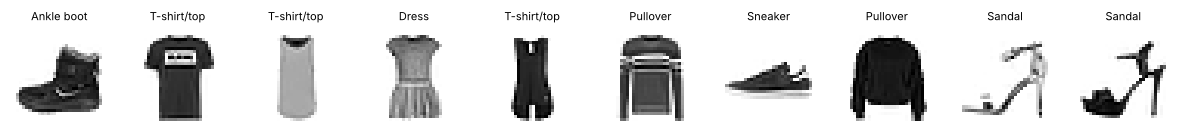

In [5]:
# Show some items of clothing from the training set
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i, :, :, 0], cmap="gray_r"); ax.set_title(CLASS_NAMES[y_train[i]], fontsize=8); ax.axis("off")
plt.show()

## 2. Build the autoencoder

In [6]:
# Encoder
encoder_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input")
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(encoder_input)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = K.int_shape(x)[1:]  # the decoder will need this!

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,770 (378.01 KB)

 Trainable params: 96,770 (378.01 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)
decoder_output = layers.Conv2D(CHANNELS, (3, 3), strides=1, activation="sigmoid",
                               padding="same", name="decoder_output")(x)

decoder = models.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,273 (962.00 KB)

 Trainable params: 246,273 (962.00 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Autoencoder
autoencoder = models.Model(encoder_input, decoder(encoder_output), name="autoencoder")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 2)              │         4,098 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 32, 32, 1)      │       246,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 343,043 (1.31 MB)

 Trainable params: 343,043 (1.31 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Train the autoencoder

In [9]:
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

history = autoencoder.fit(
    x_train, x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=2,
)

Epoch 1/3


600/600 - 43s - 71ms/step - loss: 0.2948 - val_loss: 0.2604


Epoch 2/3


600/600 - 39s - 65ms/step - loss: 0.2572 - val_loss: 0.2569


Epoch 3/3


600/600 - 39s - 66ms/step - loss: 0.2541 - val_loss: 0.2542


## 4. Reconstruct images and compare with the originals

In [10]:
predictions = autoencoder.predict(x_test, verbose=0)
mse = ((x_test - predictions) ** 2).mean(axis=(1, 2, 3))

print(f"Mean test MSE: {mse.mean():.4f}\n")
for c in range(10):
    print(f"{CLASS_NAMES[c]:<12} MSE {mse[y_test == c].mean():.4f}")

Mean test MSE: 0.0234

T-shirt/top  MSE 0.0218
Trouser      MSE 0.0156
Pullover     MSE 0.0233
Dress        MSE 0.0230
Coat         MSE 0.0229
Sandal       MSE 0.0261
Shirt        MSE 0.0226
Sneaker      MSE 0.0153
Bag          MSE 0.0384
Ankle boot   MSE 0.0247


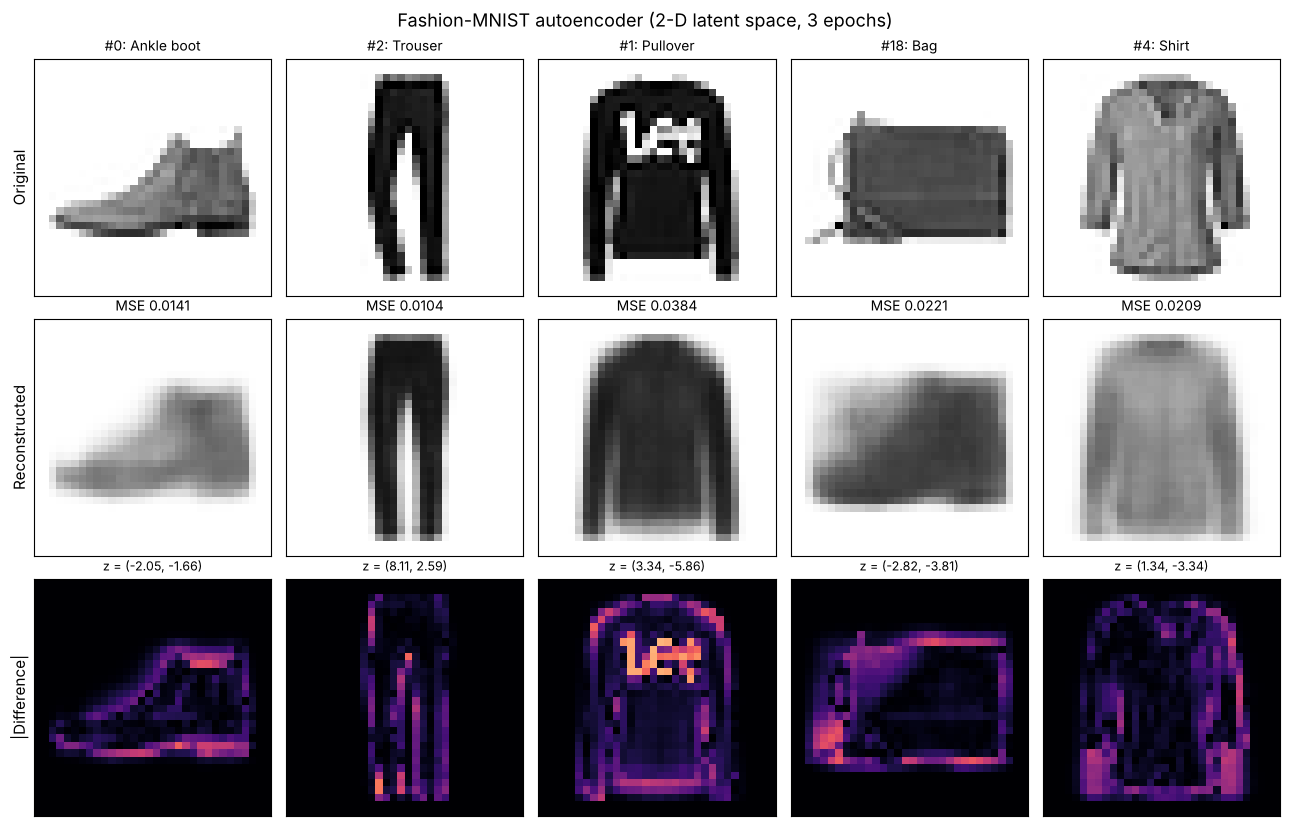

In [11]:
# Five test images of my choice, each from a different class
CHOSEN_CLASSES = [9, 1, 2, 8, 6]  # Ankle boot, Trouser, Pullover, Bag, Shirt
chosen = [int(np.where(y_test == c)[0][0]) for c in CHOSEN_CLASSES]
emb = encoder.predict(x_test[chosen], verbose=0)

fig, axes = plt.subplots(3, 5, figsize=(13, 8.4))
for i, idx in enumerate(chosen):
    orig, rec = x_test[idx, :, :, 0], predictions[idx, :, :, 0]
    axes[0, i].imshow(orig, cmap="gray_r", vmin=0, vmax=1)
    axes[0, i].set_title(f"#{idx}: {CLASS_NAMES[y_test[idx]]}", fontsize=10)
    axes[1, i].imshow(rec, cmap="gray_r", vmin=0, vmax=1)
    axes[1, i].set_title(f"MSE {mse[idx]:.4f}", fontsize=10)
    axes[2, i].imshow(np.abs(orig - rec), cmap="magma", vmin=0, vmax=1)
    axes[2, i].set_title(f"z = ({emb[i,0]:.2f}, {emb[i,1]:.2f})", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Reconstructed", fontsize=11)
axes[2, 0].set_ylabel("|Difference|", fontsize=11)
fig.suptitle(f"Fashion-MNIST autoencoder (2-D latent space, {EPOCHS} epochs)", fontsize=13)
plt.tight_layout()
plt.savefig("reconstructions.png", dpi=130)
plt.show()

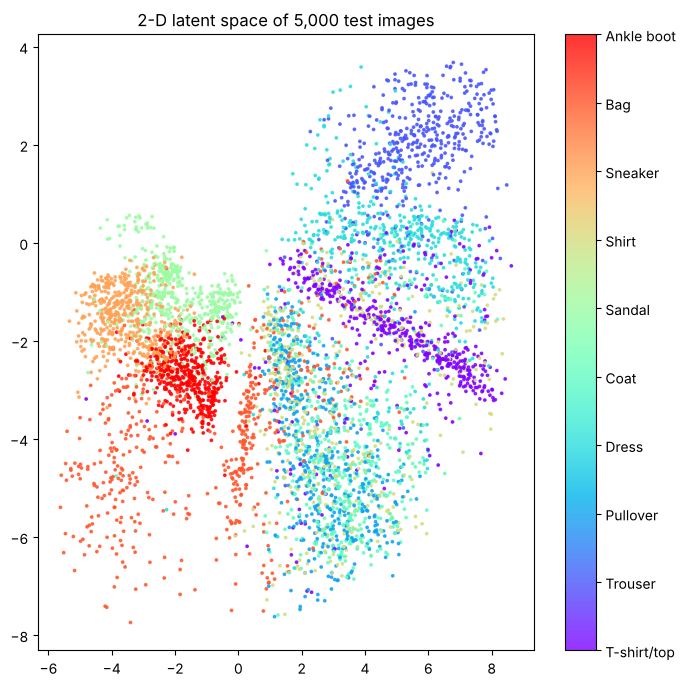

In [12]:
# The 2-D latent space, coloured by clothing type (helps explain the errors)
embeddings = encoder.predict(x_test[:5000], verbose=0)
plt.figure(figsize=(8, 8))
sc = plt.scatter(embeddings[:, 0], embeddings[:, 1], c=y_test[:5000], cmap="rainbow", s=3, alpha=0.8)
cbar = plt.colorbar(sc, ticks=range(10)); cbar.ax.set_yticklabels(CLASS_NAMES)
plt.title("2-D latent space of 5,000 test images")
plt.show()

## 5. Discrepancies between the original and reconstructed images

*(Row 1 = original, row 2 = reconstruction, row 3 = absolute pixel difference; brighter = larger error. MSE values are from the run in this notebook and may vary slightly between runs.)*

1. **Ankle boot.** The model keeps the overall boot shape and the raised ankle. The reconstruction is a smooth gray blob, though. The laces, the darker sole and the stitching are gone. The heel and toe edges are soft instead of sharp, and the shading is a flat average instead of the original's light and dark areas.

2. **Trouser (best of the five).** The two legs, the gap between them and the waistband all come through clearly. Trousers have a simple, very distinctive shape, so the 2-D code can describe them well. The main errors are slightly blurred edges along the legs and the inner gap.

3. **Pullover (worst of the five).** The silhouette is right: the body, the long sleeves and the dark color. However, the white "Lee" logo on the chest disappears completely. The reconstruction is plain black, and the difference map lights up exactly where the letters were. The decoder can only produce a typical pullover for that point in the latent space, so it can't reproduce a one-off detail like text or a logo.

4. **Bag.** The rectangular body comes back, but the handle/strap on the left is missing. The top, bottom and side edges are fuzzy, and the texture inside is uniform. Bags vary a lot in shape, so the decoder outputs a kind of "average bag" and loses features like handles. In this run the reconstruction even has a boot-like bump on its upper left. Bags sit right next to ankle boots in the 2-D latent space, so the decoder mixes in features of a nearby class.

5. **Shirt.** The general outline and the light gray color are preserved. The collar, the buttons and the cuffs at the end of each sleeve are lost. The reconstruction looks more like a generic pullover than a shirt. The latent-space plot explains why: shirts, pullovers, coats and T-shirts overlap heavily there, so the model has trouble keeping them apart.

**Overall pattern.** Every reconstruction is blurrier than its original, and fine details are lost: logos, laces, buttons, collars, handles and texture. The model does keep the coarse information, meaning the item's category, overall shape, size, position and average brightness. The main cause is the bottleneck: each 1,024-pixel image is compressed into just 2 numbers, so only the most important features survive. Binary cross-entropy loss also rewards an averaged, blurry guess over a sharp one at an uncertain pixel. That is why the errors are concentrated along edges and in high-detail areas, while plain backgrounds and solid regions match almost exactly. Simple, distinctive shapes like trousers and sneakers reconstruct best. Detailed or easily confused items, like shirts, bags and the patterned pullover, reconstruct worst. A larger latent dimension or more training epochs would probably recover more detail.